# Classificador de dígitos escritos à mão

Uma rede neural que reconhece dígitos escritos à mão (de 0 a 9), com todas as partes implementadas à mão em NumPy: forward propagation, backpropagation, função de custo regularizada, gradiente descendente e checagem pelo gradiente numérico.

- **Dados:** 5.000 dígitos escritos à mão; cada dígito é uma imagem 20x20 em tons de cinza (400 entradas).
- **Rede:** 400 entradas, 25 unidades escondidas, 10 saídas, ativação sigmoid.

**Resultados**

| Treinamento | Resultado |
|---|---|
| Com as 5.000 imagens | 94,36% de acurácia no treino |
| Divisão 60/20/20 | erro treino: 3,43%; erro validação: 8,5%; erro teste: 9,3% |
| λ escolhido pelo conjunto de validação | melhor λ = 0,01, erro de 9,4% no teste |

*Projeto de disciplina MS71 - 2s2022*

## 1. Dados
5.000 imagens de dígitos escritos à mão e seus labels.

### Importações

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
import pandas as pd
import copy
from sklearn.model_selection import train_test_split

### Leitura dos dados
Colocamos as imagens e as respostas (labels) em duas planilhas do Google Sheets.

OBS: Mudamos o label '10' que representava o número '0' para '0' na própria planilha.

In [7]:
url_images = 'https://docs.google.com/spreadsheets/d/1iVh4yFrFK1w0C8Razs-Hal7C6LVQd0s16YeaDMG-lkU/export?&format=csv'
url_labels = 'https://docs.google.com/spreadsheets/d/1yZ7x4Wf-3EiNm2BwLJaVYv_CXdVuuCQuLJP-XnvOTCs/export?&format=csv'
X = pd.read_csv(url_images, header=None, decimal=",").values
y = pd.read_csv(url_labels, header=None, decimal=",").values

### Plotando imagens aleatórias
Esses são apenas alguns exemplos das 5000 imagens 20x20 escritas à mão contidos na variável X.

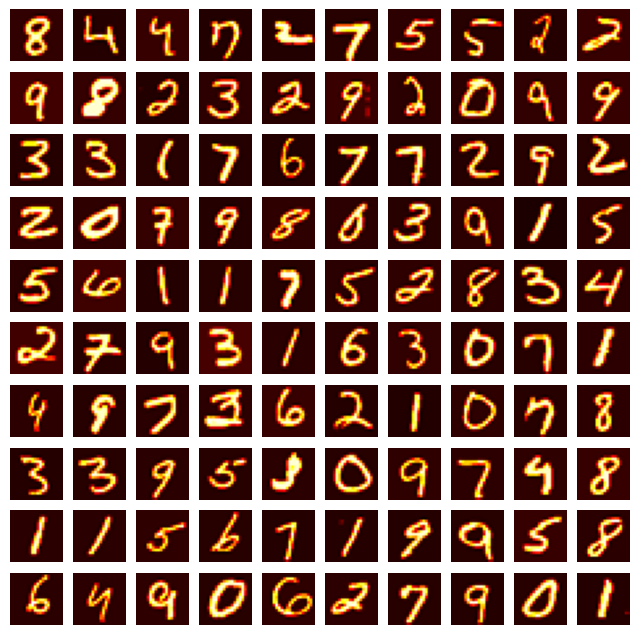

In [8]:
fig, axis = plt.subplots(10, 10, figsize = (8, 8))
for i in range(10):
    for j in range(10):
        axis[i, j].imshow(X[np.random.randint(0, 5001),:].reshape(20, 20, order="F"), cmap = "hot")
        axis[i, j].axis("off")

## 2. Implementação da rede neural
Todas as funções da rede implementadas do zero só com NumPy.

### Funções auxiliadoras
Funções usadas pelas funções de treino e de predição.

#### Função sigmoid

In [9]:
def sigmoid(z):
    return 1/(1+np.exp(-z))

#### Função flatWeights
Função que recebe uma 'lista de pesos (parâmetros)'.

Cada elemento i dessa lista é o theta_i do modelo, ou seja, uma matriz L_out x L_in com os parâmetros que cada neurônio recebe.

A partir dessa lista de pesos, a função retorna todos os pesos 'achatados' em uma lista de uma única dimensão

In [10]:
def flatWeights(list_of_weights):
    flatten_thetas = np.append(list_of_weights[0].flatten(), list_of_weights[1].flatten()) # Aqui são achatados os dois primeiros elementos (thetas) da lista
    for weight in list_of_weights[2:]: # Caso a lista tenha mais do que 2 elementos, eles são achatados e adicionados ao resto de "flatten_thetas" dentro desse "for"
        flatten_thetas = np.append(flatten_thetas, weight.flatten())
    return flatten_thetas

#### Função reshapeFlattenWeights
Função que recebe uma lista de dimensão 1 com todos os parâmetros do modelo e uma lista 'layers'.

Cada elemento i dessa lista 'layers' é o número de neurônios da camada i.

A partir disso, a função faz o reshape de cada matriz theta e retorna uma lista com todos esses thetas de cada camada.

In [11]:
def reshapeFlattenWeights(flatten_thetas, layers):
    thetas = []
    start, end = 0, 0
    for i in range(len(layers) - 1):
        L_in = layers[i] + 1 # número de neurônios da camada "i". Soma-se 1 por causa do bias.
        L_out = layers[i + 1] # número de neurônios da próxima camada. Ou seja, da camada i + 1.
        end += L_in * L_out
        theta = flatten_thetas[start:end].reshape(L_out, L_in) # pega todos os thetas que conectam as camadas (i) e (i+1) e aloca em uma matriz de L_out linhas e L_in colunas.
        thetas.append(theta) # Salva cada matriz theta em uma lista com os thetas de cada camada.

        start = end

    return thetas

#### Função randInitializeWeights
Função que recebe uma lista 'layers'. Cada elemento i dessa lista é o número de neurônios da camada i.

A partir disso, a função inicializa de forma aleatórias os pessoas para a matriz theta de cada camada e vai adicionando na lista 'thetas'.

Por fim, a função 'achata' todos esses parâmetros com a função 'flatWeights' e retorna essa lista de parâmetros de dimensão 1.

In [12]:
def randInitializeWeights(layers):
    thetas = []
    for i in range(len(layers) - 1):
      L_in = layers[i]
      L_out = layers[i+1]
      epi = (6**(1/2))/(L_in+L_out)**(1/2)
      weight = np.random.rand(L_out,L_in+1)*(2*epi)-epi
      thetas.append(weight)
    initial_theta = flatWeights(thetas)
    return initial_theta

#### Função oneHotEncode
Função que recebe os 'labels' y e uma lista 'layers' com os números de neurônios de cada camada.

A partir disso, a função faz o 'one-hot-encoding' de y, retornando uma matriz one_hot_y.

Nessa matriz one_hot_y, o número de linhas é igual ao número de exemplos, e o número de colunas é igual ao número de 'labels'.

Ou seja, se y[0] for 5, por exemplo, a primeira linha de one_hot_y será [0,0,0,0,0,1,0,0,0,0].

Se y[1], por exemplo, for 0, a segunda linha de one_hot_y será [1,0,0,0,0,0,0,0,0,0]. E assim por diante.

In [13]:
def oneHotEncode(y, layers):
    one_hot_y = np.zeros((len(y), layers[-1]))
    for i in range(layers[-1]):
        one_hot_y[:,i][:,np.newaxis] = np.where(y==i, 1, 0) # Atribui 1 em todos os espaços da coluna de one_hot_y no range(0,10) apenas se o valor de y for igual a i

    return one_hot_y

### Funções para treinar a rede neural

#### Função forwardProp
Essa função recebe m (o número de exemplos), X (imagens), theta (vetor unidimensional com todos os thetas da rede) e layers (neurônios em cada camada).

A partir disso, a função calcula os valores de ativação para cada camada e armazena-os na lista "activation_values".

Dessa forma, a função retorna uma lista na qual cada elemento "i" são os valores de ativação da camada "i".

In [14]:
def forwardProp(m, X, theta, layers):
    activation_values = []
    thetas = reshapeFlattenWeights(theta, layers)
    activation_aux = copy.deepcopy(X) # Fazendo uma cópia de X, pois ao longo dessa função, a variável "activation_aux" é modificada. Então é feita uma cópia só para garantir que X não será mudado.

    for pos, theta in enumerate(thetas):
        a = sigmoid(activation_aux @ theta.T)
        if pos != len(layers) - 2: # checando se não é a ativação da última camada. Porque, se for, não é adicionado o bias.
            a = np.hstack((np.ones((m, 1)), a)) # Adicionando o bias nos valores de ativação da camada.
            activation_aux = a
        activation_values.append(a)

    return activation_values

#### Função regularizedCostFunc
Essa função recebe m (o número de exemplos), y (labels), theta (vetor unidimensional com todos os thetas da rede), layers (neurônios em cada camada) e Lambda (fator que multiplica a parte de regularização).

A partir disso, a função calcula o custo da última camada para cada neurônio e soma esses custos em uma única variável.

A partir disso, a função retorna o custo regularizado (é um número).

In [15]:
def regularizedCostFunc(m, y, theta, layers, activation_values, Lambda):
    J = 0
    last_activation_values = activation_values[-1]
    for j in range(layers[-1]):
        J += sum(-y[:,j] * np.log(last_activation_values[:,j]) - (1-y[:,j]) * np.log(1 - last_activation_values[:,j])) # Vai somando o custo (fórmula regressão logística) de cada neurônio da última camada.

    cost = (1/m) * J # Divide pelo número de exemplos porque não queremos que o custo seja maior quanto maior o número de exemplos.
    regularization_sum = sum(np.sum(t[:, 1:]**2) for t in reshapeFlattenWeights(theta, layers)) # Eleva ao quadrado todos os thetas da rede, menos os do bias (primeira coluna de cada camada), e os soma em uma única variável.
    regularized_cost = cost + (Lambda/(2*m)) * regularization_sum

    return regularized_cost

#### Função backProp
Essa função recebe m (o número de exemplos), X (imagens), y (labels), theta (vetor unidimensional com todos os thetas da rede), layers (neurônios em cada camada), activation_values (lista com os valores de ativação de cada camada) e Lambda (fator que multiplica a parte de regularização).

A partir disso, a função executa o backpropagation e retorna uma lista "grads" com as matrizes de gradientes de cada camada da rede.

In [16]:
def backProp(m, X, y, theta, layers, activation_values, Lambda):
    thetas = reshapeFlattenWeights(theta, layers)
    grads = []
    for theta in thetas:
        grad = np.zeros((theta.shape)) # Na camada i, cada gradiente i tem o mesmo shape de theta_i, já que queremos a derivada de cada theta da camada.
        grads.append(grad)

    for i in range(m): # Para cada exemplos, nós vamos somando as derivas de theta a "grads".
        xi = X[i,:] # Primeira linha de X. Ou seja, primeiro exemplo.
        erros = [0] * (len(layers) - 1) # Lista que vai receber em cada elemento, os erros de cada camada.
        a_is = [a[i,:] for a in activation_values] # Lista em que cada elemento i é a primeira linha (primeiro exemplo) dos valores de ativação da camada i.

        # Começa a calcular os erros de tras pra frente, começando pela última camada e indo até o índice 0.
        # Isso é feito porque, a não ser que estejamos na última camada, o erro da camada (i) depende do erro da camada (i+1)
        for j in range(len(erros) - 1, -1, -1):
            if j == len(erros) - 1: # Se estivermos na última camada, o erro é simplesmente a diferença dos valores de ativação e dos valores reais ("labels").
                erros[j] = a_is[j] - y[i,:]
             # Caso contrário, o erro da camada (i) é igual ao theta da camada (i) vezes o erro da camada (i+1) vezes a derivada da sigmoid de z_i
             # OBS1: Para entender os índices j da conta abaixo (se o erro da camada i é igual ao theta da camada i, porque em baixo está thetas[j + 1]?), considere
             # essas listas de exemplo para uma rede de 4 camadas: thetas [theta1, theta2, theta3]; erros = [d2, d3, d4], a_is = [a2, a3, a4].
             # Logo o erro d3  = theta3 @ d4 * g'(z3). Mas o índice de d3 é 1, e o índice de theta3 é 2, ou seja, 1 a mais que de d3.
             # E isso vale para todos os erros (a não ser que seja o erro da última camada).
             # OBS2: g'(z_i) = ai * (1 - ai). Como passamos "activation_values" como argumento dessa função do backpropagation, ao invés de calcular g'(z_i),
             # colocamos direto a fórmula em função de a_i (já que já temos esses valores prontos).
            else:
                erros[j] = (thetas[j + 1][:, 1:].T @ erros[j + 1].T) * a_is[j][1:]*(1 - a_is[j][1:])

        # Agora, para o gradiente de cada camada, são somadas as respectivas derivadas.
        # Lembrando que as derivadas são dadas por "a_(i)" vezes "erro_(i+1)".
        for k in range(len(grads)):
            if k == 0: # Para o gradiente da primeira camada, "a_i" é na verdade o próprio xi.
                grads[k] += erros[k][:,np.newaxis] @ xi[:,np.newaxis].T
            else: # Já a partir da segunda camada, podemos considerar o próprio "a_i".
                grads[k] += erros[k][:,np.newaxis] @ a_is[k - 1][:,np.newaxis].T

    for i in range(len(grads)): # Por fim, é feita a regularização dos gradientes
        grads[i] = (1/m) * grads[i]
        # Na fórmula abaixo, é somado o termo da regularização a grads[i].
        # Esse termo nada mais é do que (Lambda/m) multiplicado por cada theta.
        # Porém, deve-se desconsidera o bias nessa soma. Logo, pegamos a partir da primeira coluna de theta (thetas[i][:,1:]))) e adicionamos 0 na nova primeira coluna com np.hstack.
        grads[i] += (Lambda/m) * np.hstack((np.zeros((thetas[i].shape[0], 1)), thetas[i][:,1:]))

    return grads # A função retorna uma lista com a matriz de gradientes de cada camada.

#### Função computeCost
Essa função recebe X (imagens), y (labels), theta (vetor unidimensional com todos os thetas da rede), layers (neurônios em cada camada), Lambda (fator que multiplica a parte de regularização) e numerical_gradient (booleano para a função saber se deve ou não efetuar a checagem pelo gradiente numérico. É falso por default).

A partir disso, a função calcula o forward propagation, o custo regularizado e os gradientes regularizados.

A função retorna, então, o custo e os gradientes. Além disso, caso a checagem pelo gradiente numérico esteja como "True", a função retorna uma lista com a norma da diferença entre o gradiente calculado com o backpropagation e o gradiente numérico para cada camada. Caso contrário, retorna uma lista vazia.


In [17]:
def computeCost(X, y, theta, layers, Lambda, numerical_gradient = False):
    grads_difference = []
    m = X.shape[0] # número de exemplos
    X = np.hstack((np.ones((m, 1)), X))
    y = oneHotEncode(y, layers)

    activation_values = forwardProp(m, X, theta, layers)
    regularized_cost = regularizedCostFunc(m, y, theta, layers, activation_values, Lambda)
    regularized_grads = backProp(m, X, y, theta, layers, activation_values, Lambda)

    if numerical_gradient:
        numerical_regularized_grads = numericalGradient(X, y, theta, activation_values, layers, Lambda, erro = 1e-4) # Cálculo do gradiente numérico.
        numerical_regularized_grads = reshapeFlattenWeights(numerical_regularized_grads, layers)
        for i in range(len(layers) - 1):
            grad = regularized_grads[i] # Gradiente do backpropagation.
            numerical_grad = numerical_regularized_grads[i] # Gradiente numérico.

            difference = grad - numerical_grad
            grads_difference.append(np.linalg.norm(difference)) # Norma da diferença.

    return regularized_cost, regularized_grads, grads_difference

#### Função gradientDescent
Essa função recebe X (imagens), y (labels), theta (vetor unidimensional com todos os thetas da rede), layers (neurônios em cada camada), alpha (taxa de aprendizado. Default = 0.8), nbr_iter (número de iterações. Default = 1000.), Lambda (fator que multiplica a parte de regularização. Default = 1) e numerical_gradient (booleano para a função saber se deve ou não efetuar a checagem pelo gradiente numérico. Default = False).

A partir disso, a função calcula os gradientes para cada iteração e atualiza os thetas.

A função retorna os thetas finais como uma lista unidimensional, o histórico de custos, e o histórico das diferenças entre o gradiente numérico e o calcuado pelo backpropagation. Caso a checagem pelo gradiente numérico esteja desabilitada, essa última variável é uma lista vazia.

In [18]:
def gradientDescent(X, y, theta, layers, alpha = 0.8, nbr_iter = 1000, Lambda = 1, numerical_gradient = False):
    thetas = reshapeFlattenWeights(theta, layers)

    m = len(y) # número de exemplos
    J_history, grads_difference_history = [], []

    for i in range(nbr_iter):
        theta = flatWeights(thetas)
        cost, grads, grads_difference = computeCost(X, y, theta, layers, Lambda, numerical_gradient)
        for i in range(len(thetas)):
            thetas[i] = thetas[i] - (alpha * grads[i])
        J_history.append(cost)
        grads_difference_history.append(grads_difference)

    nn_paramsFinal = flatWeights(thetas)
    return nn_paramsFinal, J_history, grads_difference_history

### Funções de predição
As funções utilizadas para realizar as previsões de fato, a partir dos parâmetros descobertos no treino.

#### Função prediction
Função que recebe as imagens (variável X), os "labels" (variável y), uma lista unidimensional com todos os thetas da rede neural, e uma lista "layers" com a quantidade de neurônios de cada camada.

A partir disso, a função realiza um forward propagation com o theta fornecido, pega os valores de ativação da última camada, e devolve o número que tem o maior valor de ativação, ou seja, a maior probabilidade de ser o verdadeiro.

OBS: esse número pode ser interpretado como probabilidade de o número previsto ser o correto contra outra opção. Mas vale lembrar que a soma dos valores de ativação da última camada não dá 1. Seria necessário usar o softmax ao invés da sigmoid para que o número fosse a probabilidade de fato.



In [19]:
def prediction(X, y, theta, layers):
    m = X.shape[0] # número de exemplos.
    X = np.hstack((np.ones((m,1)), X)) # Adiciona 1's na primeira coluna de X. Ou seja, adiciona o bias (lembrando que X tem 5000 linhas e 400 colunas inicialmente).
    oh_y = oneHotEncode(y, layers)

    activation_values = forwardProp(m, X, theta, layers)
    last_activation_value = activation_values[-1]

    return np.argmax(last_activation_value, axis=1)

#### Função accuracy
Essa função calcula quantas predições são iguais aos valores reais e divide esse resultado pelo número de exemplos.

A partir disso, ela retorna a acurácia no formato XX.YY (exemplo: 95.46).

In [20]:
def accuracy(X, y, theta, layers):
    accuracy = sum(prediction(X, y ,theta, layers)[:,np.newaxis] == y)[0] / len(y)
    accuracy = round(accuracy*100, 2)
    return accuracy

## 3. Checagem pelo gradiente numérico
Antes de treinar a rede de verdade, vamos fazer uma comparação entre o gradiente calculado pelo backpropagation e o gradiente calculado numericamente. Isso é feito para garantir que o backpropagation está correto. Se o backpropagation estiver correto, a diferença entre os dois gradientes deve ser praticamente zero.

### Função numericalGradient
Função que calcula os gradientes numericamente. Recebe como argumentos X (imagens), y (labels), theta (vetor unidimensional com todos os thetas da rede), activation_values (lista com os valores de ativação de cada camada), layers (neurônios em cada camada), Lambda (fator que multiplica a parte de regularização) e erro (irá dividr na fórmula da derivada. Default = 1e-4).

A função retorna um vetor unidimensional com todos os gradientes da rede.

In [21]:
def numericalGradient(X, y, theta, activation_values, layers, Lambda, erro = 1e-4):
    numerical_grads = []
    m = X.shape[0]

    for i in range(len(theta)):
        # Plus
        theta_plus = copy.deepcopy(theta)
        theta_plus[i] = theta[i] + erro
        activation_values_plus = forwardProp(m, X, theta_plus, layers)
        cost_plus = regularizedCostFunc(m, y, theta_plus, layers, activation_values_plus, Lambda)

        # Minus
        theta_minus = copy.deepcopy(theta)
        theta_minus[i] = theta[i] - erro
        activation_values_minus = forwardProp(m, X, theta_minus, layers)
        cost_minus = regularizedCostFunc(m, y, theta_minus, layers, activation_values_minus, Lambda)

        numerical_grads.append((cost_plus - cost_minus) / (2 * erro))

    numerical_grads = np.array(numerical_grads)

    return numerical_grads

### Comparando gradientes
Aqui está a comparação entre o gradiente numérico e o gradiente obtido através do backpropagation.

Para isso, a checagem foi feita em uma rede neural menor (3 neurônios na entrada, 5 na camada escondida, e 3 na saída) para apenas 3 exemplos aleatórios de treinamento.

In [22]:
numerical_X = np.array([[1,3,2],[2,3,1],[7,3,1]])
numerical_y = np.array([[1],[0],[2]])

numerical_layers = [3,5,3] # Número de neurônios em cada camada da rede
numerical_gradient = True
numerical_alpha = 0.8
numerical_nbr_iter = 200
numerical_Lambda = 1
numerical_initial_theta = randInitializeWeights(numerical_layers) # lista de dimensão 1 ('achatamento') com valores gerados aleatoriamente para a matriz theta de cada camada.

numerical_parameters, numerical_J_history, grads_difference_history = gradientDescent(numerical_X, numerical_y, numerical_initial_theta, numerical_layers, numerical_alpha, numerical_nbr_iter, numerical_Lambda, numerical_gradient)

In [23]:
# Lista em que cada linha é uma iteração. E para cada linha, tem a norma da diferença para os gradientes de cada camada.
# Aqui, está sendo mostrada essa diferença para a última iteração.
grads_difference_history[-1]

[np.float64(3.883971191134467e-09), np.float64(2.2758817986783163e-10)]

### Gráficos
Gráficos comparando as normas das diferenças entre os gradientes calculados pelo backpropagation e os gradientes calculados numericamente.

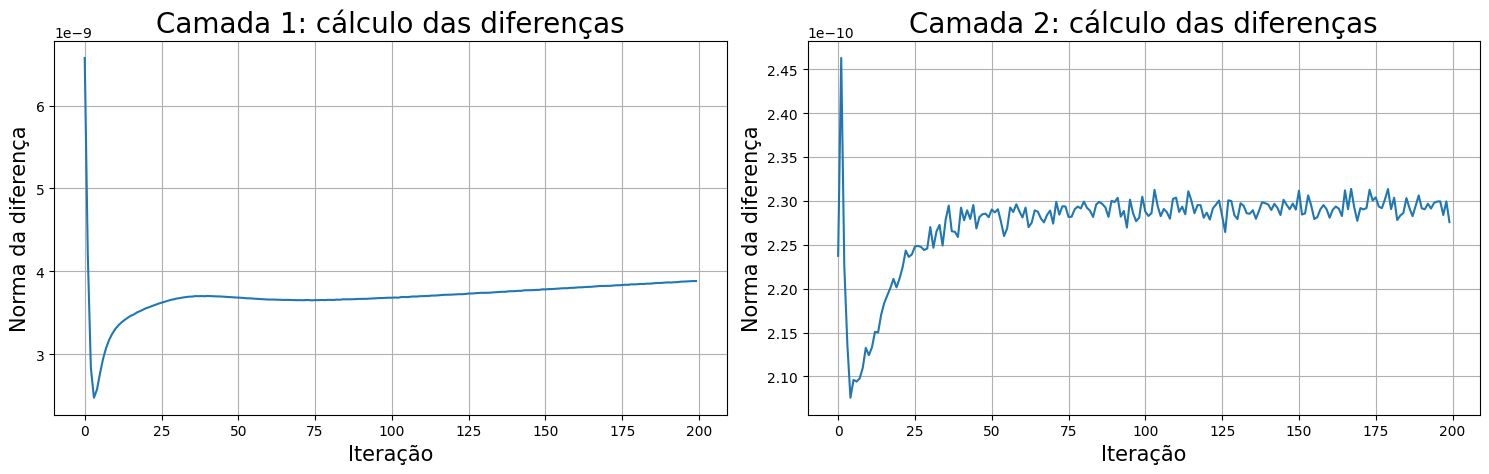

In [24]:
ImagensGrad = pd.DataFrame(grads_difference_history)
ImagensGrad = ImagensGrad.rename(columns={0:'Camada 1', 1:'Camada 2'})

fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (15,5))

ax1.set_title("Camada 1: cálculo das diferenças", fontsize = 20)
ax1.plot(ImagensGrad["Camada 1"])
ax1.set_ylabel("Norma da diferença", fontsize=15)
ax1.set_xlabel("Iteração", fontsize=15)
ax1.grid()

ax2.set_title("Camada 2: cálculo das diferenças", fontsize = 20)
ax2.plot(ImagensGrad["Camada 2"])
ax2.set_ylabel("Norma da diferença", fontsize=15)
ax2.set_xlabel("Iteração", fontsize=15)
ax2.grid()

plt.tight_layout()

## 4. Treinamento
Primeiro, a rede é treinada com todas as 5.000 imagens. Depois, vemos em quais imagens ela erra. Além disso, é possível ver o que cada unidade escondida "aprendeu".

### Treinamento da rede neural usando todos os dados para treino

In [25]:
layers = [400, 25, 10] # Número de neurônios em cada camada da rede
alpha = 0.8 # Taxa de aprendizado
nbr_iter = 800 # Número de iterações
Lambda = 1
initial_theta = randInitializeWeights(layers) # lista de dimensão 1 ('achatamento') com valores gerados aleatoriamente para a matriz theta de cada camada.

parameters, J_history, grads_difference_history = gradientDescent(X, y, initial_theta, layers, alpha, nbr_iter, Lambda)

In [26]:
train_accuracy = accuracy(X, y, parameters, layers)
print(f"Training Set Accuracy: {train_accuracy} %")

Training Set Accuracy: 94.36 %


### Imagens classificadas incorretamente
Aqui, foram selecionadas 100 imagens de maneira aleatória, com a condição que a imagem prevista seja diferente da imagem real.

Em seguida, foi criado uma DataFrame com quais valores a rede neural havia previsto, sendo que cada posição i,j desse dataframe corresponde à posição i,j da matriz com os plots.

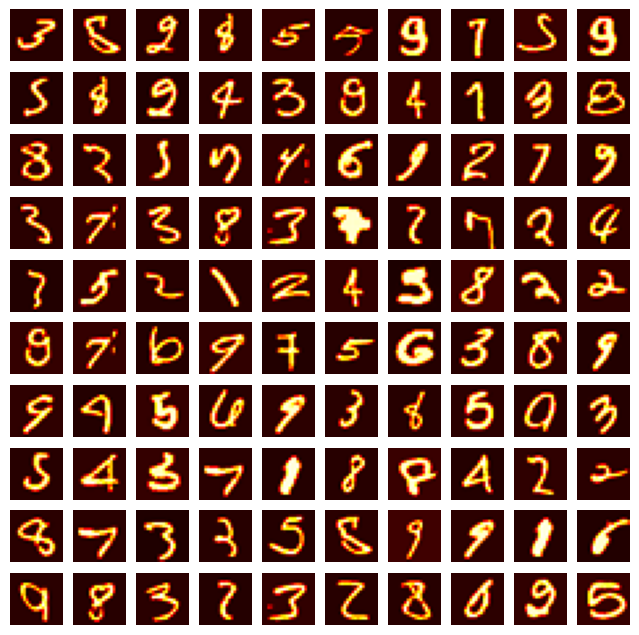

In [27]:
fig, axis = plt.subplots(10, 10, figsize = (8, 8))
lista_pred = np.zeros((10,10))

for i in range(10):
    for j in range(10):
      while True:
        idx = np.random.randint(0, 5000)
        pred = prediction(X, y, parameters, layers)
        if pred[idx] != y[idx][0]:
          lista_pred[i][j] = pred[idx]
          axis[i, j].imshow(X[idx,:].reshape(20, 20, order="F"), cmap = "hot")
          axis[i, j].axis("off")
          break

lista_pred = pd.DataFrame(lista_pred)

In [28]:
lista_pred

,0,1,2,3,4,5,6,7,8,9
0,2.0,2.0,3.0,6.0,4.0,4.0,3.0,1.0,3.0,3.0
1,3.0,6.0,3.0,9.0,5.0,0.0,1.0,9.0,9.0,0.0
2,3.0,7.0,3.0,0.0,8.0,5.0,1.0,8.0,1.0,7.0
3,5.0,1.0,5.0,9.0,7.0,8.0,1.0,4.0,9.0,6.0
4,7.0,3.0,5.0,8.0,8.0,1.0,3.0,3.0,7.0,4.0
5,0.0,1.0,0.0,7.0,1.0,8.0,0.0,5.0,5.0,7.0
6,5.0,9.0,8.0,0.0,7.0,1.0,4.0,0.0,0.0,9.0
7,6.0,2.0,5.0,4.0,7.0,1.0,7.0,2.0,3.0,4.0
8,3.0,4.0,7.0,2.0,0.0,2.0,7.0,7.0,7.0,8.0
9,7.0,9.0,5.0,1.0,7.0,8.0,3.0,3.0,0.0,0.0


### Função scale
Função que recebe um vetor unidimensional e realiza a normalização desse vetor.

In [29]:
def scale(x):
    x = (x - np.min(x)) / (np.max(x) - np.min(x))
    return x

### Atuação dos parâmetros (unidade escondida) com 1 camada escondida
Nessa parte, os thetas que conectam as camadas 1 e 2 foram plotados para cada unidade da camada 2. Ou seja, tem 25 imagens 20x20.

As variáveis "parameters" e "layers" foram definidas no treinamento acima utilizando todos os dados.

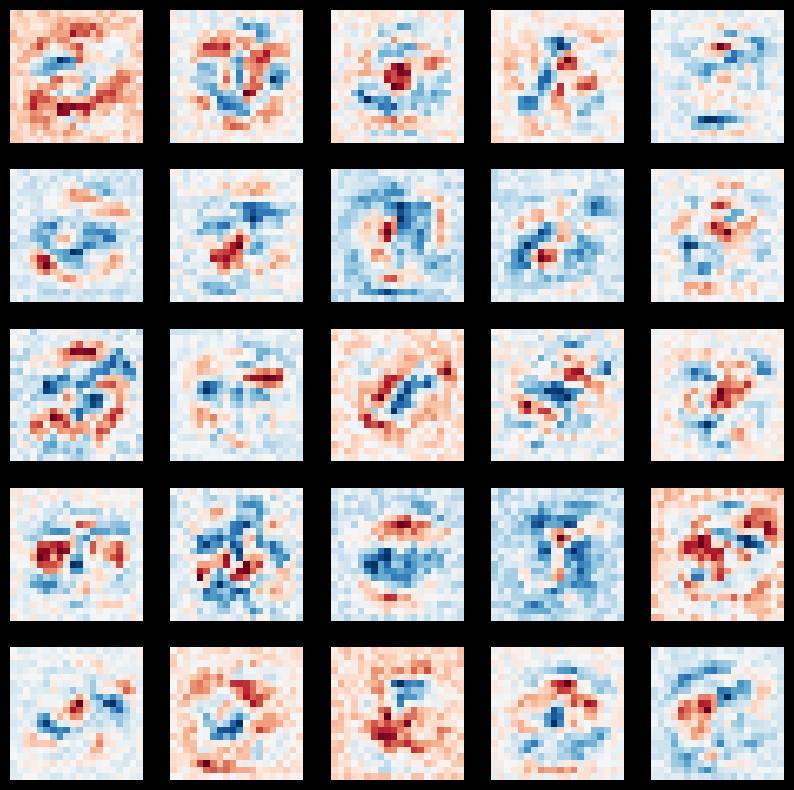

In [30]:
thetas = reshapeFlattenWeights(parameters, layers)

k = 0
fig, axis = plt.subplots(5, 5, figsize = (10, 10))
for i in range(5):
    for j in range(5):
      scaled_theta = scale(thetas[0][k][1:])
      image = scaled_theta.reshape(20, 20, order = "F")
      axis[i, j].imshow(image, cmap="RdBu")
      axis[i, j].axis("off")
      k += 1
fig.patch.set_facecolor('black')

### Atuação dos parâmetros (unidade escondida) com 2 camadas escondidas
As variáveis "parameters" e "layers" foram definidas no treinamento acima utilizando todos os dados.

In [31]:
new_layers = [400,25,25,10] # Número de neurônios em cada camada da rede
new_alpha = 0.8
new_nbr_iter = 1000
new_Lambda = 1
new_initial_theta = randInitializeWeights(new_layers) # lista de dimensão 1 ('achatamento') com valores gerados aleatoriamente para a matriz theta de cada camada.

new_parameters, new_J_history, grads_difference_history = gradientDescent(X, y, new_initial_theta, new_layers, new_alpha, new_nbr_iter, new_Lambda)

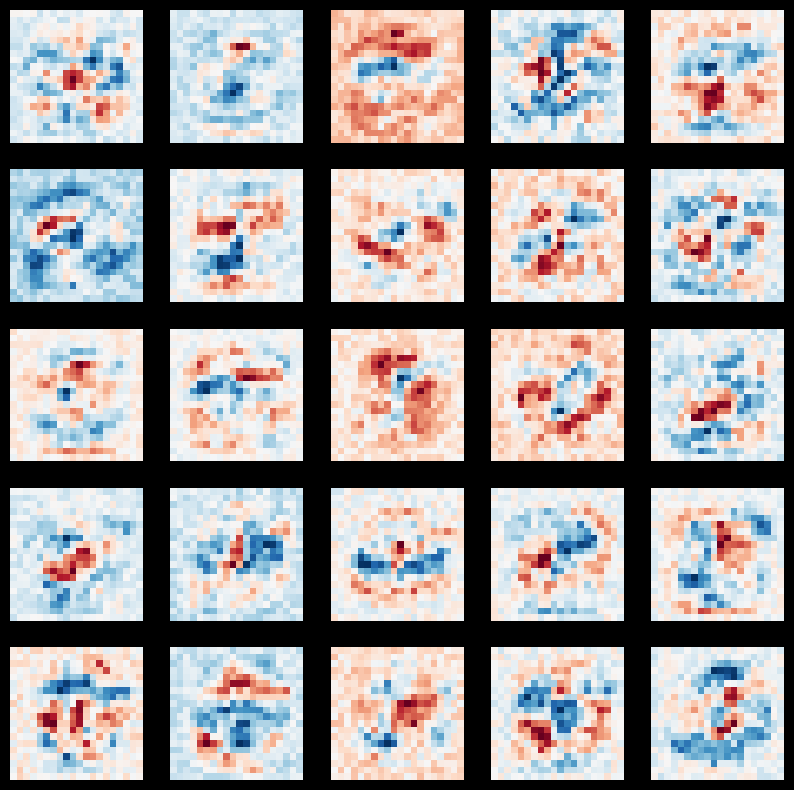

In [32]:
new_thetas = reshapeFlattenWeights(new_parameters, new_layers)

k = 0
fig, axis = plt.subplots(5, 5, figsize = (10, 10))
for i in range(5):
    for j in range(5):
      new_scaled_theta = scale(new_thetas[0][k][1:])
      new_image = new_scaled_theta.reshape(20, 20, order = "F")
      axis[i, j].imshow(new_image, cmap="RdBu")
      axis[i, j].axis("off")
      k += 1
fig.patch.set_facecolor('black')

## 5. Treinamento da rede neural e cálculo dos erros de treino, teste e validação
A acurácia da seção 4 foi medida nas mesmas imagens usadas para o treino. Nessa seção, vamos treinar a rede de novo só com parte dos dados e avaliá-la em imagens que ela nunca viu. Dessa forma, podemos garantir uma medida mais justa.

### Divisão entre dados de treino, teste e validação
Primeiro separamos 60% dos dados para treino e 40% para "test_validation".

Depois, separamos esse "test_validation" em 50% para cada, ou seja, 50% de 40% para cada.

Dessa forma, temos, no final, 60% dos dados para treino, 20% dos dados para teste, e 20% dos dados para validação.

In [33]:
X_train, X_test_validation, y_train, y_test_validation = train_test_split(X, y, train_size = 0.6, random_state = 42)
X_test, X_validation, y_test, y_validation = train_test_split(X_test_validation, y_test_validation, train_size = 0.5, random_state = 42)

### Treinamento da rede neural

In [34]:
layers = [400,25,10] # Número de neurônios em cada camada da rede
alpha = 0.8
nbr_iter = 1000
Lambda = 1
initial_theta = randInitializeWeights(layers) # lista de dimensão 1 ('achatamento') com valores gerados aleatoriamente para a matriz theta de cada camada.

parameters, J_history, grads_difference_history = gradientDescent(X_train, y_train, initial_theta, layers, alpha, nbr_iter, Lambda)

#### Treino

In [35]:
train_accuracy = accuracy(X_train, y_train, parameters, layers)
train_error = round(100 - train_accuracy, 2)
print(f"Training Set Error: {train_error} %")

Training Set Error: 3.43 %


#### Teste

In [36]:
test_accuracy = accuracy(X_test, y_test, parameters, layers)
test_error = round(100 - test_accuracy, 2)
print(f"Test Set Error: {test_error} %")

Test Set Error: 9.3 %


#### Validação

In [37]:
validation_accuracy = accuracy(X_validation, y_validation, parameters, layers)
validation_error = round(100 - validation_accuracy, 2)
print(f"Validation Set Error: {validation_error} %")

Validation Set Error: 8.5 %


## 6. Ajustando a rede
Escolha automática do λ pelo conjunto de validação e curva de aprendizado.

### Automatização da escolha de λ

#### Função listOfLambdas
Função que cria uma lista com diferentes valores de lambdas para serem testados.

In [38]:
def listOfLambdas():
    Lambdas = [0, 0.01]
    while Lambdas[-1] < 10:
        Lambdas.append(Lambdas[-1] * 2)

    return Lambdas

#### Função neuralNetworkModel
Função que recebe como argumentos X (imagens), y ("labels"), Lambdas (lista de lambdas a serem testados. Default = listOfLambdas()), alpha (taxa de aprendizado. Default = 0.8) e nbr_iter (numéro de iterações. Default = 800).

A função então divide os dados em treino, validação e teste. Depois disso, a função treina para diferentes valores de lambda, e salvo o erro do conjunto de validação para esses lambdas.

Após encontrar o lambda que minimiza o erro de validação, a função calcula o erro de teste com os parâmetros e lambdas encontrados anteriormente dentro da função.

A função então retorna os melhores parâmetros, o melhor Lambda, o erro de teste e o histórico dos erros de validação para cada Lambda.

OBS: o grupo preferiu não reincorporar o conjunto de validação no conjunto de treino antes de rodar o teste. Sabe-se que na literatura existem grupos que discordam e grupos que concordam com essa abordagem. Mas como o relatório não explicitou qual método deveria ser usado, a opção escolhida foi a de não reincorporar.

In [39]:
def neuralNetworkModel(X, y, layers, Lambdas = listOfLambdas(), alpha = 0.8, nbr_iter = 800):
    X_train, X_test_validation, y_train, y_test_validation = train_test_split(X, y, train_size = 0.6, random_state = 42)
    X_test, X_validation, y_test, y_validation = train_test_split(X_test_validation, y_test_validation, train_size = 0.5, random_state = 42)

    error_validation_history = []
    Lambdas_Thetas_Errors = {}

    for i in range(len(Lambdas)):
        Lambda = Lambdas[i]
        initial_theta = randInitializeWeights(layers) # lista de dimensão 1 ('achatamento') com valores gerados aleatoriamente para a matriz theta de cada camada.

        parameters, J_history, grads_difference_history = gradientDescent(X_train, y_train, initial_theta, layers, alpha, nbr_iter, Lambda)

        validation_error = 100 - accuracy(X_validation, y_validation, parameters, layers)
        Lambdas_Thetas_Errors[Lambda] = (parameters, validation_error)

        error_validation_history.append(validation_error)

    # A linha de código abaixo calcula o menor erro do dicionário Lambdas_Thetas_Errors e devolve o Lambda correspondente.
    best_Lambda = min(Lambdas_Thetas_Errors, key = lambda x: Lambdas_Thetas_Errors.get(x)[1])

    best_parameters, min_error = Lambdas_Thetas_Errors[best_Lambda]

    test_error = 100 - accuracy(X_test, y_test, best_parameters, layers)

    return best_parameters, best_Lambda, test_error, error_validation_history

#### Encontrando melhores parâmetros
Aqui foi rodada a função neuralNetworkModel para encontrar o melhor Lambda do modelo.

Após isso, foram plotados dois gráficos relacionando Erro e λ. Sendo o primeiro mostrando todos os λ, e o segundo mostrando apenas os 7 primeiros para uma melhor visualização.

In [40]:
layers = [400, 25, 10] # Número de neurônios em cada camada da rede

parameters, best_Lambda, test_error, error_validation_history = neuralNetworkModel(X, y, layers)

Best Lambda: 0.01
Test Error: 9.4


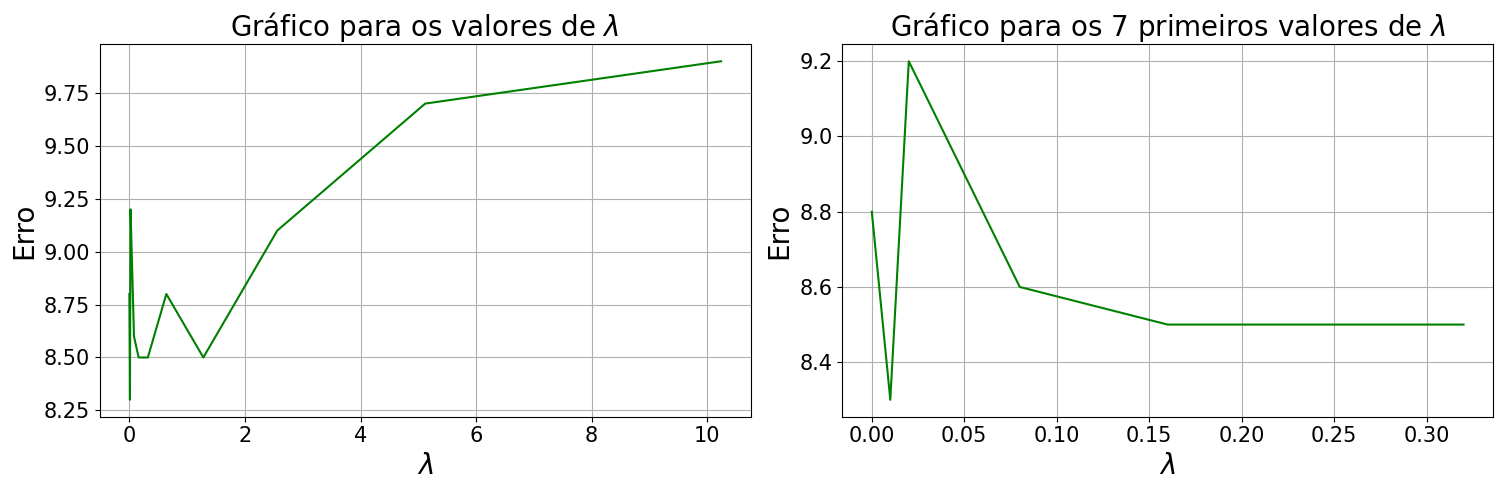

In [41]:
print(f"Best Lambda: {best_Lambda}")
print(f"Test Error: {round(test_error, 2)}")
Lambdas = listOfLambdas()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (15,5))

ax1.set_title(r"Gráfico para os valores de $\lambda$", fontsize = 20)
ax1.plot(Lambdas,error_validation_history, color="green")
ax1.set_ylabel("Erro", fontsize=20)
ax1.set_xlabel(r"$\lambda$", fontsize=20)
ax1.grid()
ax1.tick_params( labelsize=15)

ax2.set_title(r"Gráfico para os 7 primeiros valores de $\lambda$", fontsize = 20)
ax2.plot(Lambdas[:7],error_validation_history[:7], color="green")
ax2.set_ylabel("Erro", fontsize=20)
ax2.set_xlabel(r"$\lambda$", fontsize=20)
ax2.grid()
ax2.tick_params( labelsize=15)

plt.tight_layout()

### Curva de aprendizado
Este gráfico compara duas curvas, sendo o erro de treino (crescente) e o erro de validação (decrescente) em função da proporção do tamanho do conjunto de treino.

In [42]:
prop_treino = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
train_errors, validation_errors = [], []
layers = [400,25,10] # Número de neurônios em cada camada da rede
alpha = 0.8
nbr_iter = 800
Lambda = best_Lambda # Lambda que melhor minimiza o erro do conjunto de validação, encontrado acima.
initial_theta = randInitializeWeights(layers) # lista de dimensão 1 ('achatamento') com valores gerados aleatoriamente para a matriz theta de cada camada.

for idx, prop in enumerate(prop_treino):
    X_train, X_validation, y_train, y_validation = train_test_split(X, y, train_size = prop, random_state = 42)
    parameters, J_history, grads_difference_history = gradientDescent(X_train, y_train, initial_theta, layers, alpha, nbr_iter, Lambda)

    train_accuracy = accuracy(X_train, y_train, parameters, layers)
    train_error = round(100 - train_accuracy, 2)

    validation_accuracy = accuracy(X_validation, y_validation, parameters, layers)
    validation_error = round(100 - validation_accuracy, 2)

    train_errors.append(train_error)
    validation_errors.append(validation_error)

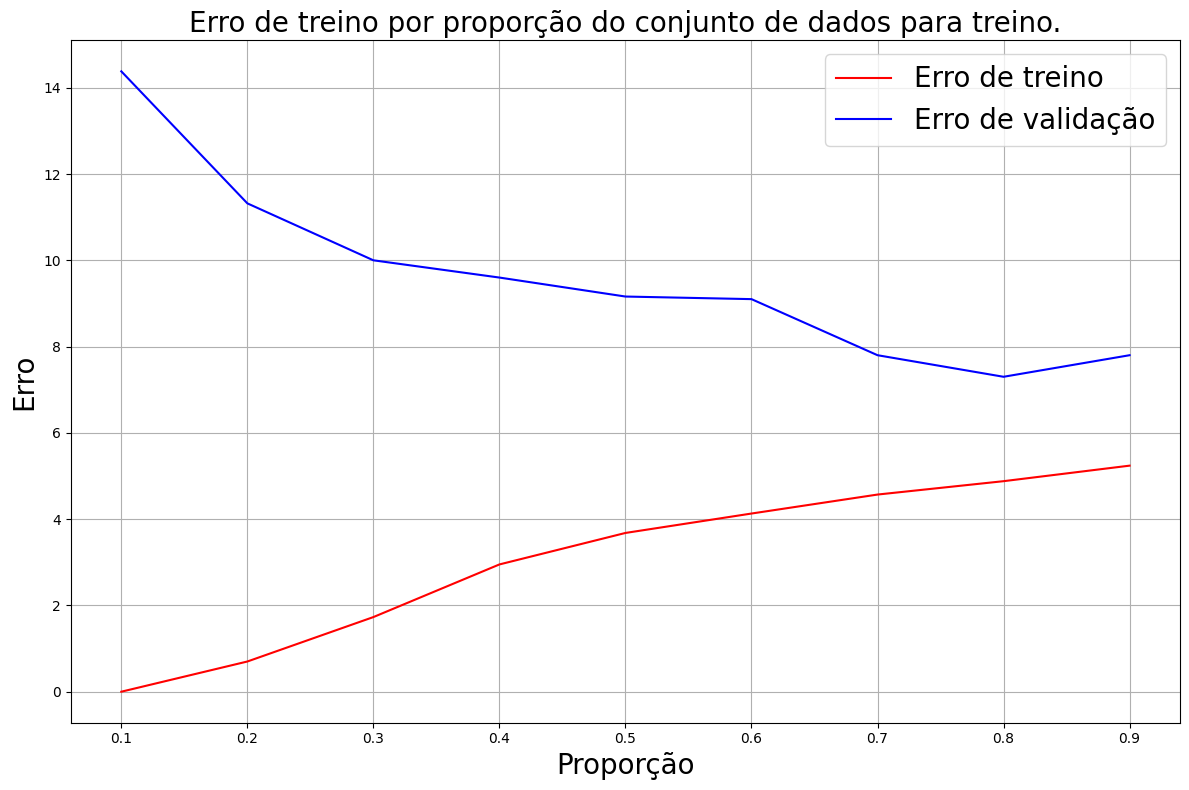

In [43]:
fig, ax = plt.subplots(1, figsize = (12,8))

ax.set_title("Erro de treino por proporção do conjunto de dados para treino.", fontsize = 20)
ax.plot(prop_treino,train_errors, color="red", label = "Erro de treino")
ax.plot(prop_treino,validation_errors, color="blue", label = "Erro de validação")
ax.set_ylabel("Erro", fontsize=20)
ax.set_xlabel("Proporção", fontsize=20)
ax.grid()
ax.tick_params( labelsize=10)
plt.legend(prop={'size': 20})

plt.tight_layout()